### SIB - Ridge Regression

A Jupyter Notebook with examples of how to use the Ridge Regression models.

In [1]:
# imports
import numpy as np
import matplotlib.pyplot as plt

from si.io.csv_file import read_csv
from si.model_selection.split import train_test_split
from si.models.ridge_regression import RidgeRegression
from si.models.ridge_regression_least_squares import RidgeRegressionLeastSquares

In [2]:
# cpu dataset (regression)
cpu_dataset = read_csv('../datasets/cpu/cpu.csv', features=True, label=True)
cpu_dataset.shape()

(209, 6)

In [3]:
# Split dataset
train_dataset, test_dataset = train_test_split(cpu_dataset, test_size=0.2, random_state=42)
train_dataset.shape(), test_dataset.shape()

((168, 6), (41, 6))

In [4]:
# Ridge regression with the default parameters
ridge = RidgeRegression()
ridge.fit(train_dataset)
print('Iterations:', len(ridge.cost_history))
print('Score (MSE):', ridge.score(test_dataset))
print('Cost:', ridge.cost(test_dataset))

Iterations: 2000
Score (MSE): 6961.627321853728
Cost: 3549.4959321574624


In [5]:
# Ridge regression with a higher learning rate
ridge_fast = RidgeRegression(l2_penalty=1.0, alpha=0.1, max_iter=5000, patience=50)
ridge_fast.fit(train_dataset)
print('Iterations:', len(ridge_fast.cost_history))
print('Score (MSE):', ridge_fast.score(test_dataset))
print('Cost:', ridge_fast.cost(test_dataset))

Iterations: 818
Score (MSE): 5806.078435819471
Cost: 2992.0334852930805


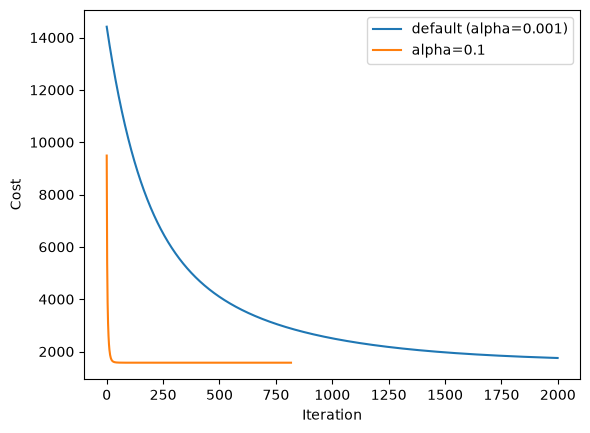

In [6]:
# Cost along the iterations
plt.plot(list(ridge.cost_history.keys()), list(ridge.cost_history.values()), label='default (alpha=0.001)')
plt.plot(list(ridge_fast.cost_history.keys()), list(ridge_fast.cost_history.values()), label='alpha=0.1')
plt.xlabel('Iteration')
plt.ylabel('Cost')
plt.legend()
plt.show()

In [7]:
# Ridge regression with least squares
ridge_ls = RidgeRegressionLeastSquares(l2_penalty=1.0)
ridge_ls.fit(train_dataset)
print('Score (MSE):', ridge_ls.score(test_dataset))
print('theta (gradient descent):', ridge_fast.theta)
print('theta (least squares):  ', ridge_ls.theta)

Score (MSE): 5806.078466084658
theta (gradient descent): [11.27246675 36.97025993 64.04886815 25.76068485  2.77451402 32.09506156]
theta (least squares):   [11.27246675 36.97025942 64.0488686  25.76068496  2.77451415 32.09506132]
